# UBL price-only MLP — multi-horizon forecasting

## A. Data preparation, features, windows, and single-split baseline

In [1]:
# A-1. IMPORTS
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, layers, callbacks
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

In [2]:
# A-2. LOAD AND CLEAN PRICE DATA
# Load the same UBL price dataset used by the source notebook.
price_path = "/kaggle/input/datasets/ba2lll/ubl-price/UBL.csv"
if not os.path.exists(price_path):
    candidates = glob.glob("/kaggle/input/**/UBL.csv", recursive=True)
    if not candidates:
        raise FileNotFoundError("Could not find UBL.csv under /kaggle/input.")
    price_path = candidates[0]
df_raw = pd.read_csv(price_path)
df_raw.columns = df_raw.columns.str.strip().str.upper()
df_raw["DATE"] = pd.to_datetime(df_raw["DATE"])
df_raw = df_raw[df_raw["DATE"] >= "2021-01-01"].drop_duplicates()
ok = ((df_raw[["OPEN","HIGH","LOW","CLOSE"]] > 0).all(axis=1) &
      (df_raw["VOLUME"] >= 0) &
      (df_raw["HIGH"] >= df_raw[["OPEN","CLOSE","LOW"]].max(axis=1)) &
      (df_raw["LOW"] <= df_raw[["OPEN","CLOSE","HIGH"]].min(axis=1)))
df = df_raw.loc[ok].sort_values("DATE").copy()
df = df[(df.DATE >= "2021-09-30") & (df.DATE <= "2026-06-30")].reset_index(drop=True)
assert df.DATE.is_unique, "Duplicate dates remain after cleaning."
print("Cleaned rows:", len(df), "| range:", df.DATE.min().date(), "to", df.DATE.max().date())
assert len(df) == 1176, f"Expected 1,176 cleaned rows; found {len(df)}. Check dataset/version and cleaning."

Cleaned rows: 1176 | range: 2021-09-30 to 2026-06-30


In [3]:
# A-3. SEVEN PRICE FEATURES
# Seven source-notebook features; do not add or remove features.
df["ret"] = np.log(df.CLOSE).diff()
df["hl_range"] = (df.HIGH - df.LOW) / df.CLOSE
df["oc_change"] = (df.CLOSE - df.OPEN) / df.OPEN
df["log_vol"] = np.log1p(df.VOLUME)
df["ma5_ratio"] = df.CLOSE / df.CLOSE.rolling(5).mean() - 1
df["ma20_ratio"] = df.CLOSE / df.CLOSE.rolling(20).mean() - 1
df["vol10"] = df.ret.rolling(10).std()
df = df.dropna().reset_index(drop=True)
feats = ["ret","hl_range","oc_change","log_vol","ma5_ratio","ma20_ratio","vol10"]
W = 30
assert len(feats) == 7
print("Feature rows after rolling-feature warmup:", len(df))

Feature rows after rolling-feature warmup: 1157


In [4]:
# A-4. 30×7 WINDOWS AND TARGETS
# Window ending at t predicts target date t+1. Keep the source notebook's 30x7 window.
X, y_return, y_price, current_close, target_dates = [], [], [], [], []
for i in range(W-1, len(df)):
    X.append(df[feats].iloc[i-W+1:i+1].to_numpy(dtype=float))
    y_return.append(np.log(df.CLOSE.iloc[i+1] / df.CLOSE.iloc[i]) if i+1 < len(df) else np.nan)
    y_price.append(df.CLOSE.iloc[i+1] if i+1 < len(df) else np.nan)
    current_close.append(df.CLOSE.iloc[i])
    target_dates.append(df.DATE.iloc[i+1] if i+1 < len(df) else pd.NaT)
# Use full raw cleaned price series to retain the final target observation.
# df's last row has no next-day target; source notebook's shift(-1) drops it.
df_feat = df.copy()
df_feat["target_ret"] = np.log(df_feat.CLOSE.shift(-1) / df_feat.CLOSE)
df_feat["target_close"] = df_feat.CLOSE.shift(-1)
df_feat["tdate"] = df_feat.DATE.shift(-1)
df_feat = df_feat.dropna(subset=feats + ["target_ret","target_close","tdate"]).reset_index(drop=True)
X_list, yr, yp, pc, td = [], [], [], [], []
for i in range(W-1, len(df_feat)):
    X_list.append(df_feat[feats].iloc[i-W+1:i+1].to_numpy(dtype=float))
    yr.append(df_feat.target_ret.iloc[i]); yp.append(df_feat.target_close.iloc[i])
    pc.append(df_feat.CLOSE.iloc[i]); td.append(df_feat.tdate.iloc[i])
X = np.asarray(X_list); y_return = np.asarray(yr); y_price = np.asarray(yp)
current_close = np.asarray(pc); target_dates = pd.to_datetime(td)
print("Window tensor:", X.shape, "| flattened inputs:", W*len(feats))
assert X.shape[1:] == (30,7) and X.reshape(len(X),-1).shape[1] == 210

Window tensor: (1127, 30, 7) | flattened inputs: 210


In [5]:
# A-5. CHRONOLOGICAL SPLIT AND FEATURE SCALING
# Chronological split boundaries are target dates, exactly as in the source notebook.
tr = np.asarray(target_dates <= pd.Timestamp("2025-01-23"))
va = np.asarray((target_dates > pd.Timestamp("2025-01-23")) & (target_dates <= pd.Timestamp("2025-10-10")))
te = np.asarray(target_dates > pd.Timestamp("2025-10-10"))
print("Train / validation / test:", tr.sum(), va.sum(), te.sum())
assert te.sum() == 177, f"Expected h=1 test rows=177; found {te.sum()}."
X_flat = X.reshape(len(X), -1)
sx = StandardScaler().fit(X_flat[tr])
X_scaled = sx.transform(X_flat)
X_train, X_val, X_test = X_scaled[tr], X_scaled[va], X_scaled[te]

Train / validation / test: 774 176 177


In [6]:
# A-6. SINGLE-SPLIT MLP MODELS
def build_mlp(n_features):
    tf.keras.utils.set_random_seed(SEED)
    model = Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

def fit_single(target, target_mask_train=tr):
    # X scaler and target scaler are fitted on training rows only.
    sy = StandardScaler().fit(target[target_mask_train].reshape(-1,1))
    model = build_mlp(X_train.shape[1])
    model.fit(X_train, sy.transform(target[tr].reshape(-1,1)),
              validation_data=(X_val, sy.transform(target[va].reshape(-1,1))),
              epochs=200, batch_size=32, verbose=0,
              callbacks=[callbacks.EarlyStopping(patience=20, restore_best_weights=True)])
    return model, sy

model_A, sy_A = fit_single(y_price)
model_B, sy_B = fit_single(y_return)
pred_A = model_A.predict(X_test, verbose=0).ravel()
pred_A = sy_A.inverse_transform(pred_A.reshape(-1,1)).ravel()
pred_B_ret = model_B.predict(X_test, verbose=0).ravel()
pred_B_ret = sy_B.inverse_transform(pred_B_ret.reshape(-1,1)).ravel()
pred_B = current_close[te] * np.exp(pred_B_ret)

I0000 00:00:1792873568.108633      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792873568.112043      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1792873572.067893     140 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


### Single-split metrics

In [7]:
# A-7. SINGLE-SPLIT METRICS
def metrics(actual, pred, prev, naive=False):
    actual, pred, prev = map(np.asarray, (actual, pred, prev))
    return {
        "MAE": MAE(actual, pred),
        "RMSE": np.sqrt(MSE(actual, pred)),
        "MAPE": np.mean(np.abs((actual-pred)/actual))*100,
        "R2": r2_score(actual, pred),
        "DirAcc": np.nan if naive else np.mean(np.sign(actual-prev) == np.sign(pred-prev))*100
    }

single_rows = []
for split_name, mask in [("Train",tr),("Validation",va),("Test",te)]:
    # Predict each split for the single-split model; target scalers are training-only.
    xa = X_scaled[mask]
    pa = sy_A.inverse_transform(model_A.predict(xa, verbose=0)).ravel()
    pb_ret = sy_B.inverse_transform(model_B.predict(xa, verbose=0)).ravel()
    pb = current_close[mask] * np.exp(pb_ret)
    actual, prev = y_price[mask], current_close[mask]
    for name, pred, naive in [("Model A (price)",pa,False),("Model B (return)",pb,False),("Naive",prev,True)]:
        single_rows.append({"Split":split_name,"Model":name,**metrics(actual,pred,prev,naive=naive)})
single_summary = pd.DataFrame(single_rows)
display(single_summary.round(3))
single_summary.to_csv("ubl_price_single_split_metrics.csv", index=False)

,Split,Model,MAE,RMSE,MAPE,R2,DirAcc
0,Train,Model A (price),35.855,47.798,20.691,0.579,50.517
1,Train,Model B (return),1.818,2.705,1.038,0.999,64.341
2,Train,Naive,2.089,3.357,1.182,0.998,NaN
3,Validation,Model A (price),289.350,320.948,72.921,-23.666,44.886
4,Validation,Model B (return),9.801,23.206,2.601,0.871,48.295
5,Validation,Naive,7.718,22.317,2.042,0.881,NaN
6,Test,Model A (price),228.717,233.506,56.415,-24.588,54.237
7,Test,Model B (return),8.615,12.157,2.132,0.931,45.763
8,Test,Naive,7.859,11.103,1.944,0.942,NaN


## B. Multi-horizon forecasting

In [10]:
# MH-1. CONFIG + HORIZON-SPECIFIC DATA
HORIZONS = [1,5,10,21]
SEED = 42
TRAIN_CUTOFF = pd.Timestamp("2025-01-23")
VAL_CUTOFF = pd.Timestamp("2025-10-10")

# Use the feature-engineered frame before next-day target dropping.
base = df.copy()
# Features in base are the same seven features created in Section A.
def build_horizon_frame(h):
    d = base.copy()
    d["target_close"] = d.CLOSE.shift(-h)
    d["tdate"] = d.DATE.shift(-h)
    d["target_ret"] = np.log(d.target_close / d.CLOSE)
    d = d.dropna(subset=feats + ["target_close","tdate","target_ret"]).reset_index(drop=True)
    # Construct 30-day feature windows ending at each eligible current-price row.
    rows = np.arange(W-1, len(d))
    Xh = np.stack([d[feats].iloc[i-W+1:i+1].to_numpy(dtype=float) for i in rows])
    out = d.iloc[rows].copy().reset_index(drop=True)
    out["X_flat"] = list(Xh.reshape(len(Xh),-1))
    return out, Xh

horizon_data = {h:build_horizon_frame(h) for h in HORIZONS}
for h,(dh,Xh) in horizon_data.items():
    test_count = int((dh.tdate > VAL_CUTOFF).sum())
    print(f"h={h}: usable samples={len(dh)}, test targets after cutoff={test_count}")

expected_counts = {1: 177, 5: 173, 10: 168, 21: 157}

for h, expected in expected_counts.items():
    d, _ = horizon_data[h]
    got = int((d.DATE >= VAL_CUTOFF).sum())

    print(f"h={h}: expected={expected}, found={got}")
    assert got == expected, (
        f"h={h}: expected {expected} test rows, found {got}. "
        "Check feature-date alignment and horizon target construction."
    )

h=1: usable samples=1127, test targets after cutoff=177
h=5: usable samples=1123, test targets after cutoff=177
h=10: usable samples=1118, test targets after cutoff=177
h=21: usable samples=1107, test targets after cutoff=177
h=1: expected=177, found=177
h=5: expected=173, found=173
h=10: expected=168, found=168
h=21: expected=157, found=157


In [15]:
# MH-2. SHARED MLP FIT/PREDICT HELPER
def build_mlp_mh(n_features):
    tf.keras.utils.set_random_seed(SEED)
    model = Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64,activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32,activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer="adam",loss="mse")
    return model

def mh_fit_predict(d, Xh, fit_idx, val_idx, test_idx):
    # Feature and target scalers are fitted on fit rows only.
    # Flatten 30 x 7 windows into 210 inputs for the MLP.
    Xh_flat = Xh.reshape(Xh.shape[0], -1)
    
    # Fit the feature scaler on fit rows only.
    sx_h = StandardScaler().fit(Xh_flat[fit_idx])
    
    Xf = sx_h.transform(Xh_flat[fit_idx])
    Xv = sx_h.transform(Xh_flat[val_idx])
    Xt = sx_h.transform(Xh_flat[test_idx])
    cur = d.CLOSE.iloc[test_idx].to_numpy()
    out={}
    for tag,col in [("A","target_close"),("B","target_ret")]:
        sy_h = StandardScaler().fit(d[col].iloc[fit_idx].to_numpy().reshape(-1,1))
        yf=sy_h.transform(d[col].iloc[fit_idx].to_numpy().reshape(-1,1))
        yv=sy_h.transform(d[col].iloc[val_idx].to_numpy().reshape(-1,1))
        model=build_mlp_mh(Xf.shape[1])
        model.fit(Xf,yf,validation_data=(Xv,yv),epochs=200,batch_size=32,verbose=0,
                  callbacks=[callbacks.EarlyStopping(patience=20,restore_best_weights=True)])
        pred=sy_h.inverse_transform(model.predict(Xt,verbose=0)).ravel()
        out[tag]=pred
    return out["A"], cur*np.exp(out["B"]), cur

In [24]:
# MH-3. ONE MODEL PER HORIZON — SINGLE CHRONOLOGICAL SPLIT WITH PURGE
mh_frames=[]
for h in HORIZONS:
    d, Xh = horizon_data[h]

    # Training and validation are bounded by target date.
    train_pool = np.flatnonzero(d.tdate <= TRAIN_CUTOFF)

    val_pool = np.flatnonzero(
        (d.tdate > TRAIN_CUTOFF) &
        (d.tdate <= VAL_CUTOFF)
    )

    # Test rows are selected by feature date.
    test_idx = np.flatnonzero(d.DATE >= VAL_CUTOFF)

    # Purge h-1 rows at partition boundaries.
    purge = h - 1
    fit_idx = train_pool[:-purge] if purge else train_pool.copy()
    val_idx = val_pool[:-purge] if purge else val_pool.copy()

    if len(fit_idx) == 0 or len(val_idx) == 0 or len(test_idx) == 0:
        raise ValueError(
            f"h={h}: empty split after purge; "
            f"fit={len(fit_idx)}, val={len(val_idx)}, test={len(test_idx)}"
        )

    assert d.tdate.iloc[fit_idx].max() <= TRAIN_CUTOFF
    assert d.tdate.iloc[val_idx].max() <= VAL_CUTOFF
    pA,pB,cur=mh_fit_predict(d,Xh,fit_idx,val_idx,test_idx)
    mh_frames.append(pd.DataFrame({
        "h":h,"DATE":d.tdate.iloc[test_idx].to_numpy(),"prev_close":cur,
        "actual":d.target_close.iloc[test_idx].to_numpy(),"pred_A":pA,"pred_B":pB
    }))
    print(f"h={h:>2} | fit={len(fit_idx)} | val={len(val_idx)} | test={len(test_idx)} | "
          f"test target range {pd.to_datetime(d.tdate.iloc[test_idx[0]]).date()} -> {pd.to_datetime(d.tdate.iloc[test_idx[-1]]).date()}")
mh_pred=pd.concat(mh_frames,ignore_index=True)
mh_pred.to_csv("ubl_price_multihorizon_single_split_predictions.csv",index=False)

h= 1 | fit=774 | val=176 | test=177 | test target range 2025-10-13 -> 2026-06-30
h= 5 | fit=766 | val=172 | test=173 | test target range 2025-10-17 -> 2026-06-30
h=10 | fit=756 | val=167 | test=168 | test target range 2025-10-24 -> 2026-06-30
h=21 | fit=734 | val=156 | test=157 | test target range 2025-11-10 -> 2026-06-30


In [22]:

# DEBUG: Find invalid prices in multi-horizon predictions

for col in ["actual", "pred_A", "pred_B", "prev_close"]:
    vals = mh_pred[col].to_numpy(dtype=float)
    bad = (~np.isfinite(vals)) | (vals <= 0)

    print(f"\n{col}: {bad.sum()} invalid rows")

    if bad.any():
        print(mh_pred.loc[bad, ["h", "DATE", col]].head(10).to_string(index=False))



actual: 0 invalid rows

pred_A: 14 invalid rows
 h       DATE     pred_A
 1 2026-03-27 -57.844627
 1 2026-04-14 -11.839745
 5 2026-04-02 -46.220844
 5 2026-04-07 -18.621370
 5 2026-04-14 -11.296556
 5 2026-04-20 -41.655750
10 2026-04-08  -2.927482
10 2026-04-09 -82.276665
10 2026-04-14 -33.123344
10 2026-04-27 -17.674522

pred_B: 0 invalid rows

prev_close: 0 invalid rows


In [26]:

# MH-4. METRICS, NAIVE BASELINE, AND SANITY CHECKS

def mh_metrics(actual, pred, prev, naive=False):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    pred = np.asarray(pred, dtype=float).reshape(-1)
    prev = np.asarray(prev, dtype=float).reshape(-1)

    # Check that prices are valid before calculating returns.
    if not (np.isfinite(actual).all()
            and np.isfinite(pred).all()
            and np.isfinite(prev).all()):
        raise ValueError(
            "Missing or infinite price values found. "
            "Inspect mh_pred before calculating metrics."
        )

    if np.any(actual <= 0) or np.any(pred <= 0) or np.any(prev <= 0):
        raise ValueError(
            "Zero or negative prices found; log returns are undefined."
        )

    a_ret = np.log(actual / prev)
    p_ret = np.log(pred / prev)

    return {
        "MAE": MAE(actual, pred),
        "RMSE": np.sqrt(MSE(actual, pred)),
        "MAPE": np.mean(np.abs((actual - pred) / actual)) * 100,
        "R2_price": r2_score(actual, pred),
        "DirAcc": np.nan if naive else
            np.mean(np.sign(actual - prev) == np.sign(pred - prev)) * 100,
        "R2_return": r2_score(a_ret, p_ret),
        "Corr_return": (
            np.corrcoef(a_ret, p_ret)[0, 1]
            if np.std(p_ret) > 0 and np.std(a_ret) > 0
            else np.nan
        )
    }


# Diagnose invalid values before calculating metrics.
for col in ["actual", "pred_A", "pred_B", "prev_close"]:
    vals = mh_pred[col].to_numpy(dtype=float)
    print(
        f"{col}: missing/non-finite={(~np.isfinite(vals)).sum()}, "
        f"zero/negative={(vals <= 0).sum()}"
    )

rows = []
always_up_rows = []

for h, g in mh_pred.groupby("h"):
    naive_mae = MAE(g.actual, g.prev_close)
    always_up = np.mean(g.actual > g.prev_close) * 100
    always_up_rows.append({
        "horizon": h,
        "Always-up (%)": always_up
    })

    for name, pred, is_naive in [
        ("Model A", g.pred_A, False),
        ("Model B", g.pred_B, False),
        ("Naive", g.prev_close, True)
    ]:
        m = mh_metrics(g.actual, pred, g.prev_close, naive=is_naive)
        rows.append({
            "horizon": h,
            "model": name,
            **m,
            "n_test": len(g),
            "MAE_vs_naive": m["MAE"] / naive_mae
        })

mh_table = pd.DataFrame(rows).set_index(
    ["horizon", "model"]
).sort_index()

always_up_table = pd.DataFrame(always_up_rows).set_index("horizon")

display(mh_table.round(3))
print("Always-up baseline (%)")
display(always_up_table.round(1))

mh_table.reset_index().to_csv(
    "ubl_price_multihorizon_metrics.csv", index=False
)
always_up_table.to_csv("ubl_price_multihorizon_always_up.csv")

expected_naive_mae = {1: 7.859, 5: 19.218, 10: 26.804, 21: 46.792}
expected_up = {1: 45.8, 5: 51.4, 10: 52.4, 21: 54.8}

for h, g in mh_pred.groupby("h"):
    nmae = MAE(g.actual, g.prev_close)
    assert np.isclose(nmae, expected_naive_mae[h], atol=0.02), (
        f"h={h}: naive MAE expected ~{expected_naive_mae[h]}, "
        f"got {nmae:.3f}. Investigate data/split alignment."
    )

    up = np.mean(g.actual > g.prev_close) * 100
    assert np.isclose(up, expected_up[h], atol=0.15), (
        f"h={h}: always-up expected ~{expected_up[h]}%, "
        f"got {up:.1f}%. Investigate data/split alignment."
    )

h1 = mh_pred[mh_pred.h == 1]
naive_r2 = r2_score(h1.actual, h1.prev_close)
assert np.isclose(naive_r2, 0.942, atol=0.003), (
    f"h=1 naive R2 expected ~0.942, got {naive_r2:.3f}."
)

actual: missing/non-finite=0, zero/negative=0
pred_A: missing/non-finite=0, zero/negative=0
pred_B: missing/non-finite=0, zero/negative=0
prev_close: missing/non-finite=0, zero/negative=0


MAE     RMSE    MAPE  R2_price  DirAcc  R2_return  \
horizon model                                                            
1       Model A  228.323  232.879  56.302   -24.451  54.237  -6722.197   
        Model B    8.615   12.157   2.132     0.931  45.763     -0.197   
        Naive      7.859   11.103   1.944     0.942     NaN     -0.001   
5       Model A  242.253  247.704  59.793   -27.333  47.977  -2486.842   
        Model B   20.346   27.290   4.975     0.656  58.382     -0.115   
        Naive     19.218   25.889   4.704     0.691     NaN     -0.004   
10      Model A  249.525  256.879  61.320   -28.765  47.024  -1255.621   
        Model B   30.653   39.616   7.525     0.292  57.143     -0.113   
        Naive     26.804   37.340   6.552     0.371     NaN     -0.007   
21      Model A  261.967  272.639  63.509   -31.777  45.223   -551.950   
        Model B   49.592   65.736  12.355    -0.905  56.051     -0.116   
        Naive     46.792   60.568  11.480    -0.618     NaN     -0.008   

                 Corr_return  n_test  MAE_vs_naive  
horizon model                                       
1       Model A       -0.087     177        29.053  
        Model B       -0.214     177         1.096  
        Naive            NaN     177         1.000  
5       Model A       -0.162     173        12.606  
        Model B        0.044     173         1.059  
        Naive            NaN     173         1.000  
10      Model A       -0.119     168         9.309  
        Model B        0.049     168         1.144  
        Naive            NaN     168         1.000  
21      Model A       -0.208     157         5.599  
        Model B        0.112     157         1.060  
        Naive            NaN     157         1.000

Always-up baseline (%)


,Always-up (%)
horizon,
1,45.8
5,51.4
10,52.4
21,54.8


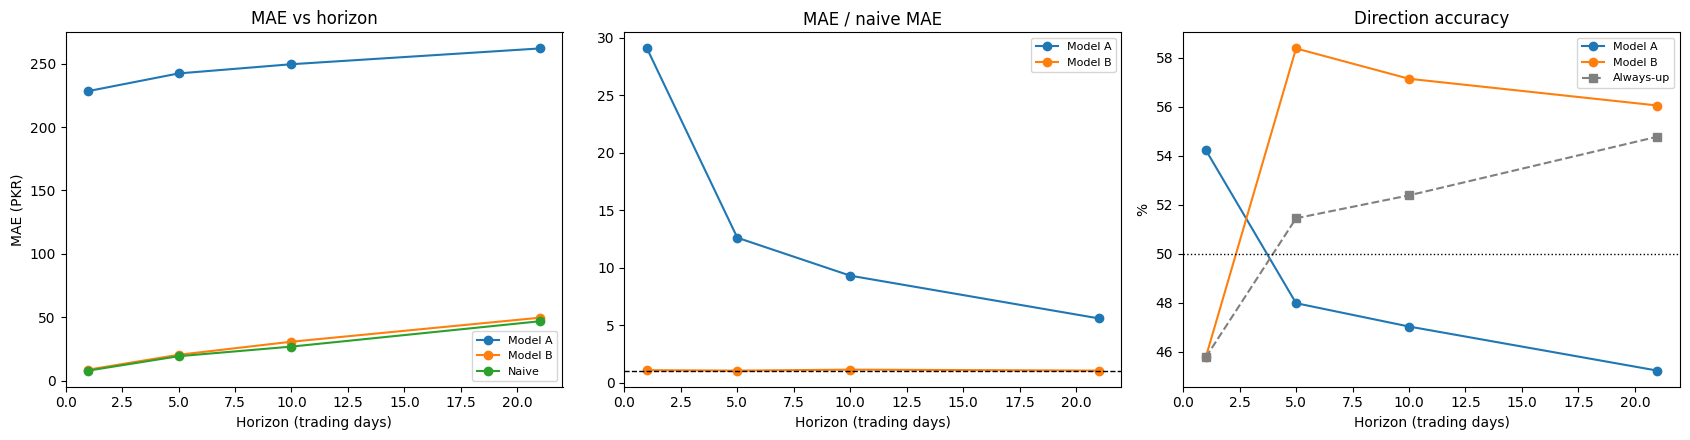

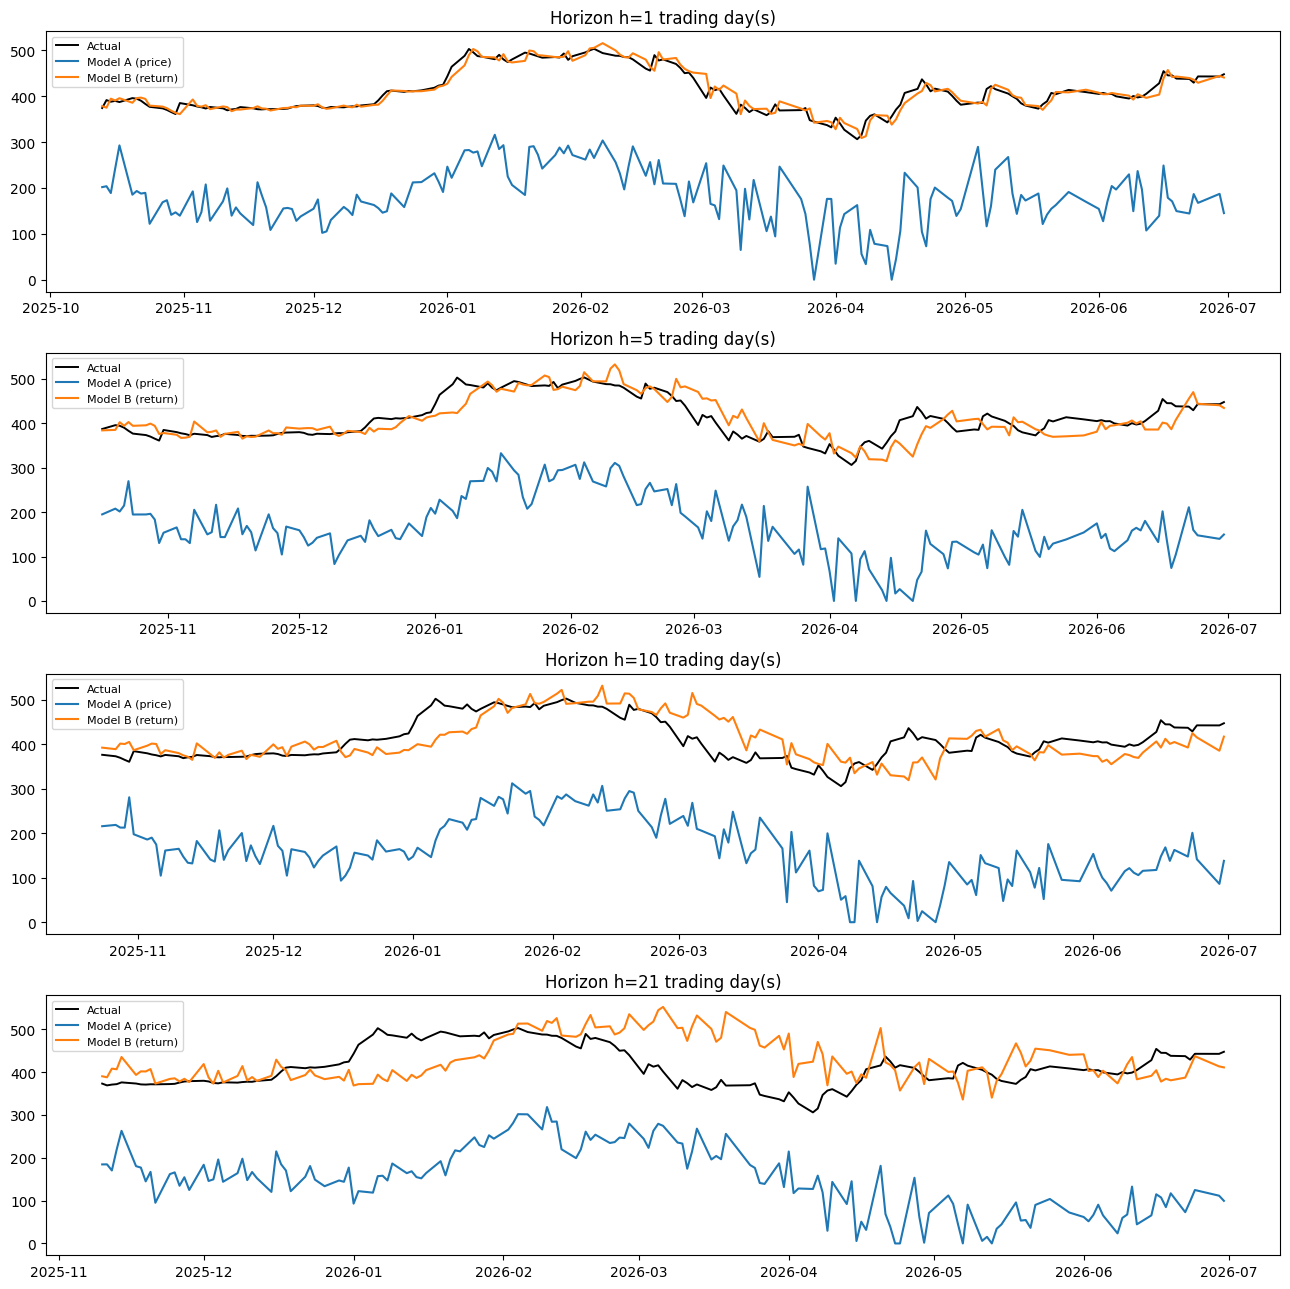

In [27]:
# MH-5. PLOTS
tbl=mh_table.reset_index()
models=["Model A","Model B","Naive"]
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for name in models:
    t=tbl[tbl.model==name]
    axes[0].plot(t.horizon,t.MAE,marker="o",label=name)
axes[0].set_title("MAE vs horizon"); axes[0].set_xlabel("Horizon (trading days)"); axes[0].set_ylabel("MAE (PKR)")
axes[0].legend(loc="best",fontsize=8)

for name in ["Model A","Model B"]:
    t=tbl[tbl.model==name]
    axes[1].plot(t.horizon,t.MAE_vs_naive,marker="o",label=name)
axes[1].axhline(1,ls="--",color="black",lw=1)
axes[1].set_title("MAE / naive MAE"); axes[1].set_xlabel("Horizon (trading days)")
axes[1].legend(loc="best",fontsize=8)

for name in ["Model A","Model B"]:
    t=tbl[tbl.model==name]
    axes[2].plot(t.horizon,t.DirAcc,marker="o",label=name)
axes[2].plot(always_up_table.index,always_up_table["Always-up (%)"],marker="s",ls="--",color="grey",label="Always-up")
axes[2].axhline(50,ls=":",color="black",lw=1)
axes[2].set_title("Direction accuracy"); axes[2].set_xlabel("Horizon (trading days)"); axes[2].set_ylabel("%")
axes[2].legend(loc="best",fontsize=8)
plt.tight_layout(); plt.savefig("ubl_price_multihorizon_metrics.png",dpi=200); plt.show()

fig,axes=plt.subplots(4,1,figsize=(13,13),sharex=False)
for ax,h in zip(axes,HORIZONS):
    g=mh_pred[mh_pred.h==h]
    ax.plot(g.DATE,g.actual,color="black",lw=1.4,label="Actual")
    ax.plot(g.DATE,g.pred_A,label="Model A (price)")
    ax.plot(g.DATE,g.pred_B,label="Model B (return)")
    ax.set_title(f"Horizon h={h} trading day(s)")
    ax.legend(loc="upper left",fontsize=8)
plt.tight_layout(); plt.savefig("ubl_price_multihorizon_predictions.png",dpi=200); plt.show()

In [28]:
# MH-6. WALK-FORWARD × MULTI-HORIZON (EXPANDING)
RUN_WF_MH=True
MH_WF_STEP=21
MH_WF_INNER_VAL=0.15

if RUN_WF_MH:
    wfmh_frames=[]
    for h in HORIZONS:
        d,Xh=horizon_data[h]
        first_test=int(np.flatnonzero(d.tdate > VAL_CUTOFF)[0])
        for fold,start in enumerate(range(first_test,len(d),MH_WF_STEP),start=1):
            end=min(start+MH_WF_STEP,len(d))
            test_idx=np.arange(start,end)
            pool=np.arange(0,start)
            eligible=pool[pool+h <= start]
            nval=max(1,int(np.ceil(len(eligible)*MH_WF_INNER_VAL)))
            cut=len(eligible)-nval-h
            if cut<1: raise ValueError(f"h={h}, fold={fold}: insufficient training rows after purge.")
            fit_idx=eligible[:cut]
            val_idx=eligible[cut+h:]
            if len(val_idx)==0: raise ValueError(f"h={h}, fold={fold}: empty inner validation.")
            train_end=pd.to_datetime(d.tdate.iloc[eligible[-1]])
            test_start=pd.to_datetime(d.tdate.iloc[test_idx[0]])
            print(f"h={h:>2} fold={fold:>2} | fit={len(fit_idx)} val={len(val_idx)} test={len(test_idx)} | train end {train_end.date()} < test start {test_start.date()}: {train_end < test_start}")
            assert train_end < test_start, f"Temporal leakage for h={h}, fold={fold}."
            pA,pB,cur=mh_fit_predict(d,Xh,fit_idx,val_idx,test_idx)
            wfmh_frames.append(pd.DataFrame({"h":h,"fold":fold,"DATE":d.tdate.iloc[test_idx].to_numpy(),
                "prev_close":cur,"actual":d.target_close.iloc[test_idx].to_numpy(),"pred_A":pA,"pred_B":pB}))
    wfmh_pred=pd.concat(wfmh_frames,ignore_index=True)
    wfmh_pred.to_csv("ubl_price_walkforward_multihorizon_predictions.csv",index=False)
    wf_rows=[]
    for h,g in wfmh_pred.groupby("h"):
        naive_mae=MAE(g.actual,g.prev_close)
        for name,pred in [("Model A",g.pred_A),("Model B",g.pred_B),("Naive",g.prev_close)]:
            wf_rows.append({"horizon":h,"model":name,"MAE":MAE(g.actual,pred),"MAE_vs_naive":MAE(g.actual,pred)/naive_mae,"n_test":len(g)})
    wfmh_table=pd.DataFrame(wf_rows).set_index(["horizon","model"]).sort_index()
    print("WALK-FORWARD × MULTI-HORIZON"); display(wfmh_table.round(3))
    single_ratio=mh_table[["MAE_vs_naive"]].rename(columns={"MAE_vs_naive":"single_split"})
    wf_ratio=wfmh_table[["MAE_vs_naive"]].rename(columns={"MAE_vs_naive":"walk_forward"})
    print("MAE_vs_naive: single split vs walk-forward")
    display(single_ratio.join(wf_ratio).round(3))
    wfmh_table.reset_index().to_csv("ubl_price_walkforward_multihorizon_metrics.csv",index=False)

h= 1 fold= 1 | fit=806 val=143 test=21 | train end 2025-10-10 < test start 2025-10-13: True
h= 1 fold= 2 | fit=824 val=146 test=21 | train end 2025-11-10 < test start 2025-11-11: True
h= 1 fold= 3 | fit=842 val=149 test=21 | train end 2025-12-09 < test start 2025-12-10: True
h= 1 fold= 4 | fit=860 val=152 test=21 | train end 2026-01-08 < test start 2026-01-09: True
h= 1 fold= 5 | fit=877 val=156 test=21 | train end 2026-02-09 < test start 2026-02-10: True
h= 1 fold= 6 | fit=895 val=159 test=21 | train end 2026-03-10 < test start 2026-03-11: True
h= 1 fold= 7 | fit=913 val=162 test=21 | train end 2026-04-10 < test start 2026-04-13: True
h= 1 fold= 8 | fit=931 val=165 test=21 | train end 2026-05-12 < test start 2026-05-13: True
h= 1 fold= 9 | fit=949 val=168 test=9 | train end 2026-06-15 < test start 2026-06-16: True
h= 5 fold= 1 | fit=795 val=142 test=21 | train end 2025-10-06 < test start 2025-10-13: True
h= 5 fold= 2 | fit=813 val=145 test=21 | train end 2025-11-04 < test start 2025-1

MAE  MAE_vs_naive  n_test
horizon model                                 
1       Model A  162.753        20.710     177
        Model B    8.393         1.068     177
        Naive      7.859         1.000     177
5       Model A  171.344         8.991     177
        Model B   22.166         1.163     177
        Naive     19.057         1.000     177
10      Model A  188.760         7.333     177
        Model B   34.660         1.347     177
        Naive     25.740         1.000     177
21      Model A  200.502         4.589     177
        Model B   56.390         1.291     177
        Naive     43.689         1.000     177

MAE_vs_naive: single split vs walk-forward


single_split  walk_forward
horizon model                              
1       Model A        29.053        20.710
        Model B         1.096         1.068
        Naive           1.000         1.000
5       Model A        12.606         8.991
        Model B         1.059         1.163
        Naive           1.000         1.000
10      Model A         9.309         7.333
        Model B         1.144         1.347
        Naive           1.000         1.000
21      Model A         5.599         4.589
        Model B         1.060         1.291
        Naive           1.000         1.000

## C. Recommended Plots

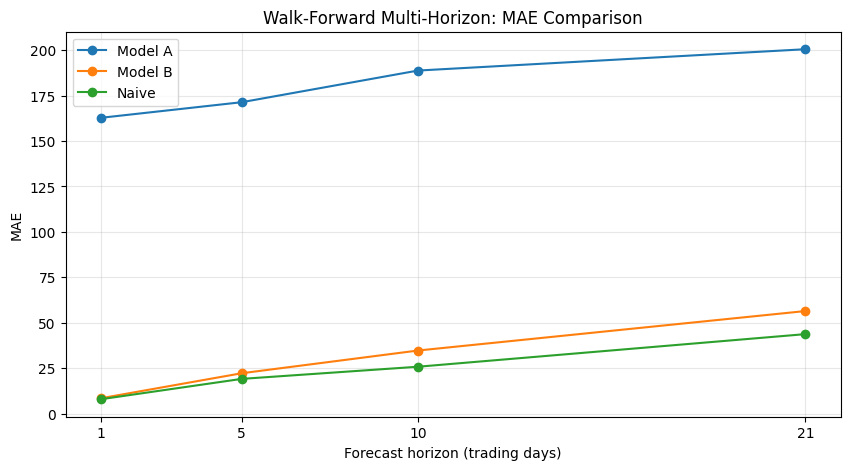

In [35]:
# MH-7. WALK-FORWARD MAE BY HORIZON
plot_data = wfmh_table.reset_index()

plt.figure(figsize=(10, 5))

for model in ["Model A", "Model B", "Naive"]:
    subset = plot_data[plot_data["model"] == model].sort_values("horizon")
    plt.plot(
        subset["horizon"],
        subset["MAE"],
        marker="o",
        label=model
    )

plt.xlabel("Forecast horizon (trading days)")
plt.ylabel("MAE")
plt.title("Walk-Forward Multi-Horizon: MAE Comparison")
plt.xticks(HORIZONS)
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    "mh7_walkforward_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

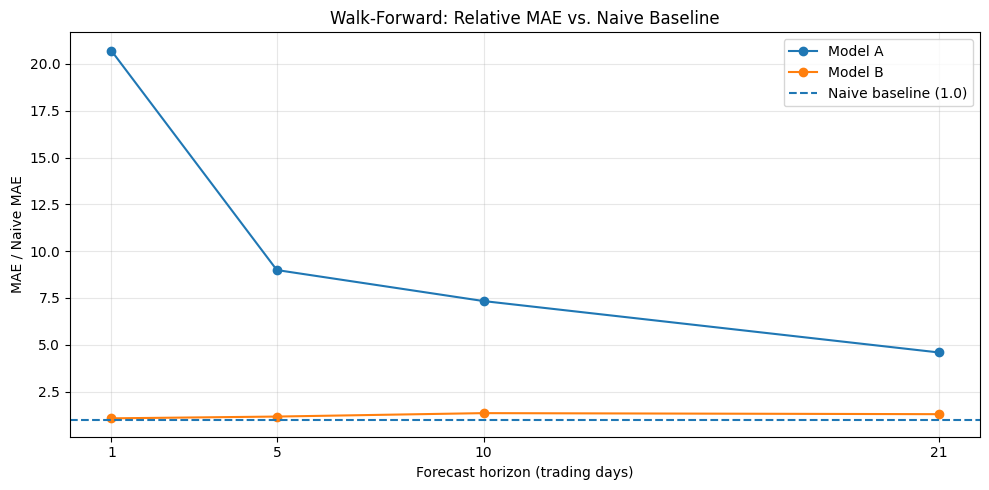

In [34]:
# MH-8. WALK-FORWARD MAE RELATIVE TO NAIVE
ratio_data = wfmh_table.reset_index()

plt.figure(figsize=(10, 5))

for model in ["Model A", "Model B"]:
    subset = ratio_data[ratio_data["model"] == model].sort_values("horizon")
    plt.plot(
        subset["horizon"],
        subset["MAE_vs_naive"],
        marker="o",
        label=model
    )

plt.axhline(1.0, linestyle="--", label="Naive baseline (1.0)")
plt.xlabel("Forecast horizon (trading days)")
plt.ylabel("MAE / Naive MAE")
plt.title("Walk-Forward: Relative MAE vs. Naive Baseline")
plt.xticks(HORIZONS)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "mh8_walkforward_mae_vs_naive.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()